# EDA A6 – Gdzie odpadają kupujący?

Pytanie biznesowe: **jak wygląda ścieżka od wejścia na stronę do zakupu i na którym etapie tracimy najwięcej osób?**

Tabela `events` to log zachowania na stronie: każde wyświetlenie strony, dodanie do koszyka, zakup.
Jedna **sesja** (`session_id`) = jedna wizyta. W A1 ustaliliśmy, że 46,5% zdarzeń nie ma `user_id`
(niezalogowani), więc **lejek liczymy po sesjach, nie po użytkownikach**.

**Nowe podejście:** `events` ma 2,4 mln wierszy (385 MB). Zamiast wczytywać je do pandas,
**agregujemy w BigQuery (SQL)**, a do pandas trafia tylko mały wynik – setki wierszy zamiast milionów.
`run_query()` przed każdym zapytaniem pokazuje, ile danych przetworzy.

Zasady:
* bierzemy tylko pełne miesiące: zdarzenia sprzed **`@cutoff`** (początek bieżącego miesiąca) –
  parametr zapytania zamiast wklejania daty do SQL,
* w A1 wyszło, że `events` ma rekordy z przyszłymi datami – filtr `@cutoff` je odcina.

## Ustawienia

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from google.cloud import bigquery

from bq_utils import run_query, DATASET
from viz_style import apply_style, legend_outside, COLORS

apply_style()

thousands = FuncFormatter(lambda v, _: f"{v / 1000:,.0f} tys.".replace(",", " "))

In [2]:
# Cutoff = first day of the current month (UTC) – only full months, no future-dated events

checked_at = pd.Timestamp.now(tz="UTC")
cutoff = checked_at.normalize().replace(day=1)

params = [bigquery.ScalarQueryParameter("cutoff", "TIMESTAMP", cutoff.to_pydatetime())]

print(f"Sprawdzono: {checked_at:%Y-%m-%d %H:%M} UTC, zdarzenia przed: {cutoff:%Y-%m-%d}")

Sprawdzono: 2026-10-29 10:53 UTC, zdarzenia przed: 2026-10-01


## 0. Jakość danych: czy sesja jest spójna?

Zanim zbudujemy lejek, sprawdzamy założenia:
* czy w jednej sesji jest zawsze jedno źródło ruchu, jedna przeglądarka i jeden użytkownik?
  (jeśli tak – możemy przypisać sesji jedno `traffic_source`),
* ile sesji jest anonimowych.

**Nowe w SQL:** `COUNTIF(warunek)` liczy wiersze spełniające warunek, `LOGICAL_OR(warunek)` w grupie zwraca TRUE,
jeśli warunek był spełniony choć raz – idealne do pytań „czy w tej sesji był zakup?”.

In [3]:
sql_quality = f"""
WITH sessions AS (
  SELECT
    session_id,
    COUNT(*)                        AS events,
    COUNT(DISTINCT traffic_source)  AS sources,
    COUNT(DISTINCT browser)         AS browsers,
    COUNT(DISTINCT user_id)         AS users,
    LOGICAL_OR(user_id IS NULL)     AS has_anonymous_event,
    LOGICAL_OR(user_id IS NOT NULL) AS has_logged_event
  FROM `{DATASET}.events`
  WHERE created_at < @cutoff
  GROUP BY session_id
)
SELECT
  COUNT(*)                                             AS sessions,
  SUM(events)                                          AS events,
  ROUND(AVG(events), 2)                                AS avg_events_per_session,
  MAX(sources)                                         AS max_sources_per_session,
  MAX(browsers)                                        AS max_browsers_per_session,
  MAX(users)                                           AS max_users_per_session,
  COUNTIF(has_anonymous_event AND has_logged_event)    AS mixed_sessions,
  ROUND(COUNTIF(NOT has_logged_event) / COUNT(*) * 100, 1) AS anonymous_sessions_pct
FROM sessions
"""

run_query(sql_quality, params).T.rename(columns={0: "value"})

Zapytanie przetworzy: 160.89 MB


,value
sessions,662088
events,2311765
avg_events_per_session,3.49
max_sources_per_session,1
max_browsers_per_session,1
max_users_per_session,1
mixed_sessions,0
anonymous_sessions_pct,74.8


## 1. Lejek zakupowy

Dla każdej sesji sprawdzamy, czy dotarła do danego kroku: **produkt → koszyk → zakup**.
`GROUP BY ROLLUP(logged_in)` dodaje do wyników wiersz z sumą dla wszystkich sesji (z `logged_in = NULL`) –
w jednym zapytaniu dostajemy podział na zalogowanych / anonimowych i całość.

In [4]:
sql_funnel = f"""
WITH sessions AS (
  SELECT
    session_id,
    LOGICAL_OR(user_id IS NOT NULL)    AS logged_in,
    LOGICAL_OR(event_type = 'product') AS saw_product,
    LOGICAL_OR(event_type = 'cart')    AS added_to_cart,
    LOGICAL_OR(event_type = 'cancel')  AS cancelled,
    LOGICAL_OR(event_type = 'purchase') AS purchased
  FROM `{DATASET}.events`
  WHERE created_at < @cutoff
  GROUP BY session_id
)
SELECT
  logged_in,
  COUNT(*)               AS sessions,
  COUNTIF(saw_product)   AS product,
  COUNTIF(added_to_cart) AS cart,
  COUNTIF(cancelled)     AS cart_cancel,
  COUNTIF(purchased)     AS purchase
FROM sessions
GROUP BY ROLLUP(logged_in)
ORDER BY logged_in
"""

funnel_raw = run_query(sql_funnel, params)
funnel_raw["segment"] = funnel_raw["logged_in"].map({True: "zalogowani", False: "anonimowi"}).fillna("wszystkie")
funnel_raw = funnel_raw.set_index("segment").drop(columns="logged_in")

funnel_raw

Zapytanie przetworzy: 143.38 MB


,sessions,product,cart,cart_cancel,purchase
segment,,,,,
wszystkie,662088,662086,413300,123256,166555
anonimowi,495205,495205,246419,123256,0
zalogowani,166883,166881,166881,0,166555


In [5]:
# Conversion between steps (% of the previous step) and overall session conversion rate

steps = ["sessions", "product", "cart", "purchase"]

conversion = pd.DataFrame({
    "product_from_session_pct": funnel_raw["product"] / funnel_raw["sessions"] * 100,
    "cart_from_product_pct": funnel_raw["cart"] / funnel_raw["product"] * 100,
    "purchase_from_cart_pct": funnel_raw["purchase"] / funnel_raw["cart"] * 100,
    "cancel_from_cart_pct": funnel_raw["cart_cancel"] / funnel_raw["cart"] * 100,
    "session_cvr_pct": funnel_raw["purchase"] / funnel_raw["sessions"] * 100,
}).round(1)

conversion

,product_from_session_pct,cart_from_product_pct,purchase_from_cart_pct,cancel_from_cart_pct,session_cvr_pct
segment,,,,,
wszystkie,100.0,62.4,40.3,29.8,25.2
anonimowi,100.0,49.8,0.0,50.0,0.0
zalogowani,100.0,100.0,99.8,0.0,99.8


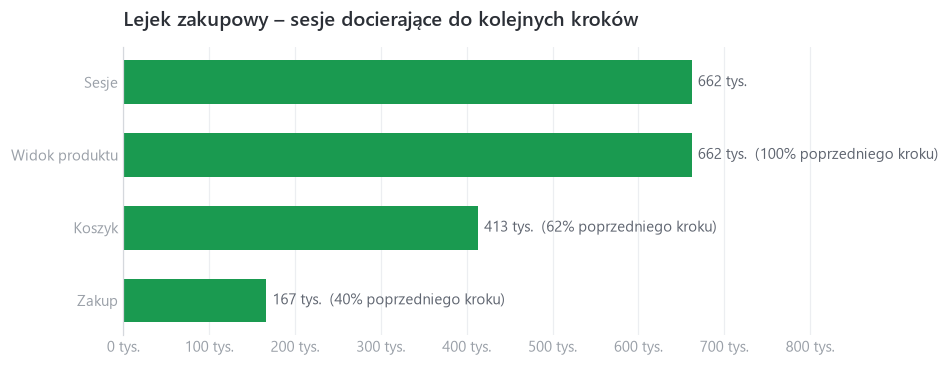

In [6]:
# Chart: purchase funnel for all sessions – bar = sessions reaching the step, label = % of the previous step

labels_pl = {"sessions": "Sesje", "product": "Widok produktu", "cart": "Koszyk", "purchase": "Zakup"}
values = funnel_raw.loc["wszystkie", steps].astype(float)

fig, ax = plt.subplots(figsize=(9, 3.4))
y = [labels_pl[s] for s in steps][::-1]
ax.barh(y, values[::-1], height=0.6, color=COLORS["series_1"])

for i, step in enumerate(steps[::-1]):
    value = values[step]
    previous = values[steps[steps.index(step) - 1]] if step != "sessions" else None
    label = f"{value / 1000:,.0f} tys.".replace(",", " ")
    if previous:
        label += f"  ({value / previous * 100:.0f}% poprzedniego kroku)"
    ax.annotate(label, xy=(value, i), xytext=(4, 0), textcoords="offset points",
                va="center", color=COLORS["text_secondary"])

ax.set_title("Lejek zakupowy – sesje docierające do kolejnych kroków")
ax.margins(x=0.35)                                          # room for the labels
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(thousands)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(False)
plt.show()

## 2. Typowe ścieżki w sesji

`STRING_AGG(event_type, ' > ' ORDER BY sequence_number)` skleja zdarzenia sesji w jeden napis
w kolejności, w jakiej wystąpiły – np. `department > product > cart`. Potem liczymy, jak często występuje każda ścieżka.
`SUM(COUNT(*)) OVER ()` – funkcja okna z A1 – daje sumę wszystkich sesji, żeby policzyć udział.

In [7]:
sql_paths = f"""
WITH paths AS (
  SELECT
    session_id,
    LOGICAL_OR(user_id IS NOT NULL)                         AS logged_in,
    COUNT(*)                                                AS events,
    STRING_AGG(event_type, ' > ' ORDER BY sequence_number)  AS path
  FROM `{DATASET}.events`
  WHERE created_at < @cutoff
  GROUP BY session_id
)
SELECT
  logged_in,
  path,
  ANY_VALUE(events)                                      AS events,
  COUNT(*)                                               AS sessions,
  ROUND(COUNT(*) / SUM(COUNT(*)) OVER () * 100, 1)       AS sessions_pct
FROM paths
GROUP BY logged_in, path
ORDER BY sessions DESC
LIMIT 10
"""

paths = run_query(sql_paths, params)
paths["path"] = paths["path"].str.slice(0, 70)              # long paths shortened for display

paths

Zapytanie przetworzy: 162.75 MB


,logged_in,path,events,sessions,sessions_pct
0,False,department > product,2,124823,18.9
1,False,product,1,123963,18.7
2,False,product > cart > cancel,3,123256,18.6
3,False,department > product > cart,3,123163,18.6
4,True,home > department > product > cart > purchase,5,80237,12.1
5,True,department > product > cart > department > pro...,7,45790,6.9
6,True,department > product > cart > department > pro...,13,23059,3.5
7,True,department > product > cart > department > pro...,10,17469,2.6
8,True,department > product > cart > department > pro...,6,171,0.0
9,True,department > product > cart > department > pro...,12,101,0.0


## 3. Konwersja wg źródła ruchu sesji i przeglądarki

Jedno zapytanie zwraca liczby sesji dla każdej kombinacji źródło × przeglądarka × zalogowany –
kilkadziesiąt wierszy. Dalsze podziały robi już pandas (zasada z `CLAUDE.md`: BigQuery agreguje, pandas dokańcza).

In [8]:
sql_segments = f"""
WITH sessions AS (
  SELECT
    session_id,
    ANY_VALUE(traffic_source)           AS traffic_source,   -- one source per session (checked in section 0)
    ANY_VALUE(browser)                  AS browser,
    LOGICAL_OR(user_id IS NOT NULL)     AS logged_in,
    LOGICAL_OR(event_type = 'cart')     AS added_to_cart,
    LOGICAL_OR(event_type = 'purchase') AS purchased
  FROM `{DATASET}.events`
  WHERE created_at < @cutoff
  GROUP BY session_id
)
SELECT
  traffic_source, browser, logged_in,
  COUNT(*)               AS sessions,
  COUNTIF(added_to_cart) AS cart,
  COUNTIF(purchased)     AS purchase
FROM sessions
GROUP BY traffic_source, browser, logged_in
"""

segments = run_query(sql_segments, params)
print(f"Wierszy w wyniku: {len(segments)}")


def session_kpi(df, by):
    return (df.groupby(by)[["sessions", "cart", "purchase"]].sum()
              .assign(logged_in_pct=lambda x: df[df["logged_in"]].groupby(by)["sessions"].sum() / x["sessions"] * 100,
                      cart_rate_pct=lambda x: x["cart"] / x["sessions"] * 100,
                      session_cvr_pct=lambda x: x["purchase"] / x["sessions"] * 100)
              .round(1)
              .sort_values("session_cvr_pct", ascending=False))


session_kpi(segments, "traffic_source")

Zapytanie przetworzy: 182.48 MB
Wierszy w wyniku: 50


,sessions,cart,purchase,logged_in_pct,cart_rate_pct,session_cvr_pct
traffic_source,,,,,,
Organic,33064,20701,8468,25.7,62.6,25.6
YouTube,66251,41459,16732,25.3,62.6,25.3
Email,298421,186392,75063,25.2,62.5,25.2
Adwords,198060,123692,49794,25.2,62.5,25.1
Facebook,66292,41056,16498,24.9,61.9,24.9


In [9]:
session_kpi(segments, "browser")

,sessions,cart,purchase,logged_in_pct,cart_rate_pct,session_cvr_pct
browser,,,,,,
IE,33155,20739,8376,25.3,62.6,25.3
Safari,132398,82812,33507,25.4,62.5,25.3
Firefox,132692,82854,33442,25.3,62.4,25.2
Chrome,330856,206331,82966,25.1,62.4,25.1
Other,32987,20564,8264,25.1,62.3,25.1


## 4. Atrybucja: z jakiego źródła przyszła sesja z zakupem?

W A1 rozróżniliśmy dwa pojęcia:
* `users.traffic_source` – **kanał pozyskania** (pierwszy kontakt, *first touch*),
* `events.traffic_source` – **źródło konkretnej sesji**; dla sesji z zakupem to *last touch*.

W reklamie to kluczowe pytanie: **komu przypisać zakup?** Jeśli klient pozyskany z Facebooka wraca i kupuje
po wejściu z wyszukiwarki, model *first touch* zaliczy zakup Facebookowi, a *last touch* – wyszukiwarce.

**Uwaga – dwa różne słowniki kanałów:** `users` ma Search, Organic, Facebook, Email, Display, a `events` –
Adwords, Email, Facebook, Organic, YouTube. Wspólne są tylko **Email, Facebook i Organic**. Bez wspólnego słownika
kanałów (np. czy „Adwords” to płatna część „Search”?) pełne porównanie first vs last touch nie jest możliwe –
to częsty problem w prawdziwych danych marketingowych.

Dla wspólnych kanałów sprawdzamy: czy klient pozyskany z kanału X częściej wraca z tego samego kanału,
niż wynikałoby z przypadku? Jeśli źródło sesji nie zależy od kanału pozyskania, każdy wiersz tabeli poniżej wygląda tak samo.

In [10]:
sql_attribution = f"""
WITH purchase_sessions AS (
  SELECT
    session_id,
    MAX(user_id)              AS user_id,
    ANY_VALUE(traffic_source) AS session_source
  FROM `{DATASET}.events`
  WHERE created_at < @cutoff
  GROUP BY session_id
  HAVING LOGICAL_OR(event_type = 'purchase')
)
SELECT
  u.traffic_source  AS acquisition_source,
  p.session_source,
  COUNT(*)          AS purchase_sessions
FROM purchase_sessions AS p
JOIN `{DATASET}.users` AS u ON u.id = p.user_id
GROUP BY acquisition_source, session_source
"""

attribution = run_query(sql_attribution, params)

print("Kanały pozyskania (users):", sorted(attribution["acquisition_source"].unique()))
print("Źródła sesji (events):    ", sorted(attribution["session_source"].unique()))

# Row = acquisition channel (first touch), columns = session source (last touch), each row = 100%
(attribution
 .pivot_table(index="acquisition_source", columns="session_source", values="purchase_sessions", aggfunc="sum")
 .pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100)
 .round(1))

Zapytanie przetworzy: 164.86 MB
Kanały pozyskania (users): ['Display', 'Email', 'Facebook', 'Organic', 'Search']
Źródła sesji (events):     ['Adwords', 'Email', 'Facebook', 'Organic', 'YouTube']


session_source,Adwords,Email,Facebook,Organic,YouTube
acquisition_source,,,,,
Display,29.4,45.6,9.7,4.9,10.4
Email,30.0,44.7,10.5,4.9,9.9
Facebook,29.8,45.3,9.6,5.3,10.0
Organic,30.0,44.8,10.1,5.1,10.0
Search,29.9,45.1,9.9,5.1,10.1


In [11]:
# Shared channels only: does a customer acquired via X come back via X more often than chance?
# expected = share of channel X among ALL purchase sessions (what we would see if source were random)

shared = sorted(set(attribution["acquisition_source"]) & set(attribution["session_source"]))
session_share = attribution.groupby("session_source")["purchase_sessions"].sum()
session_share = session_share / session_share.sum() * 100

rows = {}
for channel in shared:
    acquired = attribution[attribution["acquisition_source"] == channel]
    rows[channel] = {
        "purchase_sessions": acquired["purchase_sessions"].sum(),
        "same_source_pct": acquired.loc[acquired["session_source"] == channel, "purchase_sessions"].sum()
                           / acquired["purchase_sessions"].sum() * 100,
        "expected_if_random_pct": session_share[channel],
    }

(pd.DataFrame(rows).T
 .assign(difference_pp=lambda x: x["same_source_pct"] - x["expected_if_random_pct"])
 .round(1))

,purchase_sessions,same_source_pct,expected_if_random_pct,difference_pp
Email,8424.0,44.7,45.1,-0.4
Facebook,9935.0,9.6,9.9,-0.3
Organic,24643.0,5.1,5.1,-0.0


## 5. Ruch w czasie

Sesje miesięcznie (wg początku sesji), z podziałem na zalogowane i anonimowe, oraz konwersja sesji w czasie.

In [12]:
sql_monthly = f"""
WITH sessions AS (
  SELECT
    session_id,
    MIN(created_at)                     AS started_at,
    LOGICAL_OR(user_id IS NOT NULL)     AS logged_in,
    LOGICAL_OR(event_type = 'purchase') AS purchased
  FROM `{DATASET}.events`
  WHERE created_at < @cutoff
  GROUP BY session_id
)
SELECT
  DATE_TRUNC(DATE(started_at), MONTH) AS month,
  COUNTIF(logged_in)                  AS logged_sessions,
  COUNTIF(NOT logged_in)              AS anonymous_sessions,
  COUNTIF(purchased)                  AS purchase_sessions
FROM sessions
GROUP BY month
ORDER BY month
"""

monthly = (run_query(sql_monthly, params)
           .assign(month=lambda x: pd.to_datetime(x["month"]),
                   sessions=lambda x: x["logged_sessions"] + x["anonymous_sessions"],
                   session_cvr_pct=lambda x: x["purchase_sessions"] / x["sessions"] * 100)
           .set_index("month"))

monthly.tail(13).round(1)

Zapytanie przetworzy: 143.38 MB


,logged_sessions,anonymous_sessions,purchase_sessions,sessions,session_cvr_pct
month,,,,,
2025-09-01,3677,5198,3677,8875,41.4
2025-10-01,3799,5402,3799,9201,41.3
2025-11-01,3841,5279,3841,9120,42.1
2025-12-01,4332,5524,4332,9856,44.0
2026-01-01,4455,5347,4455,9802,45.4
2026-02-01,4195,4856,4195,9051,46.3
2026-03-01,4770,5460,4770,10230,46.6
2026-04-01,5007,5262,5007,10269,48.8
2026-05-01,5452,5473,5452,10925,49.9


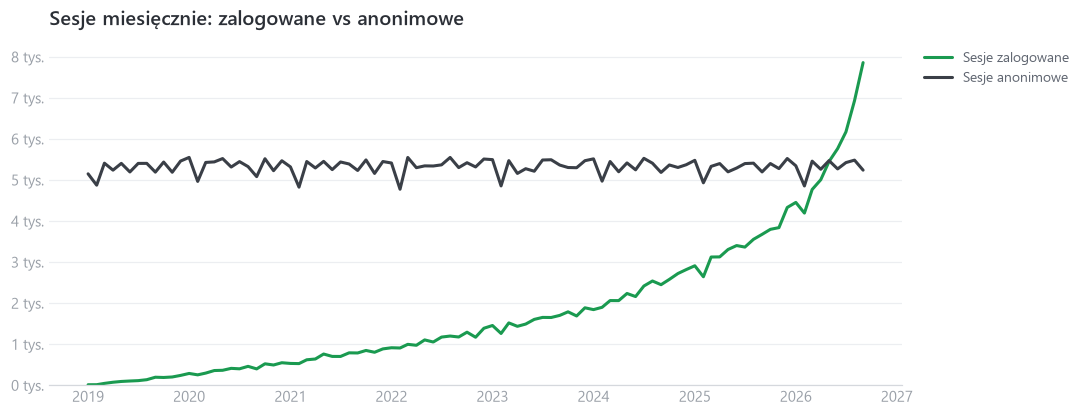

In [13]:
# Chart: monthly sessions – logged-in vs anonymous

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["logged_sessions"], color=COLORS["series_1"], label="Sesje zalogowane")
ax.plot(monthly.index, monthly["anonymous_sessions"], color=COLORS["series_2"], label="Sesje anonimowe")

ax.set_title("Sesje miesięcznie: zalogowane vs anonimowe")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(bottom=0)
legend_outside(ax)
plt.show()

## Wnioski (uzupełnij po uruchomieniu)

1.
2.
3.